# Risk, not just the average: VaR and CVaR for the newsvendor

`newsvendor.ipynb` in this folder chose one order to maximise average profit, and ended by asking
what happens if you guard the worst scenario instead. The worst single scenario is a blunt thing to
guard. This notebook guards the worst quarter of them, two ways.

**Value at Risk** at 75% is the profit you beat in three scenarios out of four: a threshold.
**Conditional Value at Risk** at 75% is the average profit across the worst quarter: the tail
itself. One of them is a linear program and the other needs an integer variable per scenario.

## Setup: where the package lives

This notebook builds its models by hand and then checks them against `orteach`, the package in
`src/`. Run from a clone of the repository, `../../src` is right there. On Colab there is no clone
until this cell makes one, and no `gurobipy` until it installs it. Nothing here needs a secret.

In [1]:
import os, subprocess, sys

REPO_URL = "https://github.com/sear-labs/teaching-code"
REF = "v1.0.1"                               # the release this notebook ships in: Colab clones THIS

try:
    import google.colab                      # noqa: F401 - succeeds only on Colab
    ON_COLAB = True
except ImportError:
    ON_COLAB = False

if ON_COLAB:
    if not os.path.isdir("/content/teaching-code"):
        subprocess.run(["git", "clone", "--quiet", "--depth", "1", "--branch", REF, REPO_URL, "/content/teaching-code"], check=True)
    os.chdir("/content/teaching-code/notebooks/07_stochastic_and_newsvendor")
    subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "gurobipy>=11,<14"], check=True)

sys.path.insert(0, os.path.abspath(os.path.join("..", "..", "src")))
try:
    import orteach                            # noqa: F401
except ImportError:
    raise SystemExit("orteach not found: run this notebook from its own folder inside the repository, "
                     "so that ../../src exists.")
root = os.path.abspath(os.path.join("..", ".."))
print("package:", os.path.relpath(os.path.dirname(orteach.__file__), root))

package: src\orteach


## Licence setup

Nothing here needs a key. `pip install gurobipy` ships a licence limited to two thousand variables
and constraints, and every model below is built to fit inside it (the next section says how). A machine
with its own licence file uses that instead, and on Colab three secrets read from the key icon in
the left sidebar are used when they are there. The environment starts silent, so no licence number
lands in an output cell.

In [2]:
import gurobipy as gp
from gurobipy import GRB

env = gp.Env(empty=True)
env.setParam("OutputFlag", 0)        # start silent: the licence banner, and its licence number, stay out of the outputs
try:
    from google.colab import userdata
    try:
        env.setParam("WLSACCESSID", userdata.get("GRB_WLSACCESSID"))
        env.setParam("WLSSECRET",   userdata.get("GRB_WLSSECRET"))
        env.setParam("LICENSEID",   int(userdata.get("GRB_LICENSEID")))
        licence = "Colab Secrets (WLS)"
    except (userdata.SecretNotFoundError, userdata.NotebookAccessError):
        licence = "the size-limited licence pip ships"     # no key needed; see the note above
except ImportError:
    licence = "local gurobi.lic"
env.start()
print("licence:", licence)

licence: local gurobi.lic


## The economics and the scenarios

The same newspaper as `newsvendor.ipynb`: each copy costs 2, sells for 15, and an unsold copy costs 3
to dispose of. The demand scenarios are that notebook's table, but only the first 400 of them. Every
model here has about four variables per scenario, so 400 keeps the largest under the free
licence's two thousand; a full licence can raise `SCENARIOS`. With `ALPHA` at 0.75 the tail is exactly
100 scenarios, so "the worst quarter" means a whole number of them.

In [3]:
from statistics import mean
from orteach import tolerance
from orteach.data import load_demand

COST, RETAIL, RECOVER = 2, 15, -3
ALPHA = 0.75
SCENARIOS = 400

demand = load_demand()[:SCENARIOS]
TAIL = round((1 - ALPHA) * SCENARIOS)
print(f"{len(demand)} scenarios, demand from {min(demand):.1f} to {max(demand):.1f}, mean {mean(demand):.1f}")
print(f"ALPHA {ALPHA}: the worst quarter is {TAIL} scenarios")

400 scenarios, demand from 33.4 to 731.2, mean 398.8
ALPHA 0.75: the worst quarter is 100 scenarios


## Two numbers for the tail, for an order you pick

Score an order of 400 copies against every scenario, then sort the profits. VaR is the profit in
position `TAIL` of the sorted list (beaten in three scenarios out of four); CVaR is the mean of the
`TAIL` profits below it. Predict before running: which is larger, and by roughly how much?

In [4]:
ORDER_GUESS = 400
guess_profits = [RETAIL * min(ORDER_GUESS, d) - COST * ORDER_GUESS + RECOVER * max(0, ORDER_GUESS - d)
                 for d in demand]
ranked = sorted(guess_profits)
guess_var, guess_cvar = ranked[TAIL], mean(ranked[:TAIL])
print(f"order {ORDER_GUESS}: mean {mean(guess_profits):.2f}   VaR {guess_var:.2f}   CVaR {guess_cvar:.2f}")

order 400: mean 4495.20   VaR 4024.31   CVaR 2894.04


## CVaR as a linear program

The average of the worst 100 profits looks like it needs sorting, which no LP can do. The way round
it (Rockafellar and Uryasev): CVaR is the largest value of $\nu - \frac{1}{100}\sum_i \max(0,\ \nu -
\text{profit}_i)$ over all $\nu$. Give each scenario an `excess` variable at least $\nu -
\text{profit}_i$ and at least zero, and the max disappears.

The rest is the newsvendor skeleton: one `order` with no scenario index (decided before demand is
seen), and `sales` and `discount` per scenario (decided after). `BETA` weighs the average against
the tail: 1 is pure CVaR, 0 is the average alone.

In [5]:
mc = gp.Model("CVaR", env=env)
tolerance.apply(mc)
order = mc.addVar(name="order")
profit = mc.addVars(SCENARIOS, lb=-GRB.INFINITY, name="profit")
sales = mc.addVars(SCENARIOS, ub=demand, name="sales")
discount = mc.addVars(SCENARIOS, name="discount")
mc.addConstrs((profit[i] == RETAIL * sales[i] - COST * order + RECOVER * discount[i] for i in range(SCENARIOS)), name="profit")
mc.addConstrs((sales[i] + discount[i] == order for i in range(SCENARIOS)), name="demand")

nu = mc.addVar(lb=-GRB.INFINITY, name="nu")
excess = mc.addVars(SCENARIOS, name="excess")                 # >= 0 by default
mc.addConstrs((excess[i] >= nu - profit[i] for i in range(SCENARIOS)), name="excess")

BETA = 1.0
mc.setObjective((1 - BETA) * profit.sum() / SCENARIOS + BETA * (nu - excess.sum() / TAIL), GRB.MAXIMIZE)
mc.update()
print(mc.NumVars, "variables,", mc.NumConstrs, "constraints")

1602 variables, 1200 constraints


Predict before running: will the CVaR order be larger or smaller than the 400 you scored by hand,
and will its average profit be higher or lower?

In [6]:
mc.optimize()
cvar_order = order.X
cvar_objective = mc.ObjVal
cvar_profits = [RETAIL * min(cvar_order, d) - COST * cvar_order + RECOVER * max(0, cvar_order - d) for d in demand]
ranked = sorted(cvar_profits)
print(f"CVaR order {cvar_order:.4f}   objective {cvar_objective:.4f}")
print(f"scored:  mean {mean(cvar_profits):.2f}   VaR {ranked[TAIL]:.2f}   CVaR {mean(ranked[:TAIL]):.2f}")

CVaR order 306.6096   objective 3285.4101
scored:  mean 3810.80   VaR 3985.92   CVaR 3285.41


The profits were scored again from the order rather than read off `profit[i].X`. Hold that thought;
the VaR model below is where it matters.

## Turning the dial

The same model with `BETA` at 0 is the risk-neutral newsvendor; at one half it splits the
difference. Only the objective changes, so set a new one and solve again.

In [7]:
mc.setObjective(profit.sum() / SCENARIOS, GRB.MAXIMIZE)                       # BETA = 0
mc.optimize()
neutral_order = order.X
mc.setObjective(0.5 * profit.sum() / SCENARIOS + 0.5 * (nu - excess.sum() / TAIL), GRB.MAXIMIZE)   # BETA = 0.5
mc.optimize()
mix_order = order.X
print(f"BETA 0: order {neutral_order:.4f}     BETA 0.5: order {mix_order:.4f}     BETA 1: order {cvar_order:.4f}")

BETA 0: order 459.7374     BETA 0.5: order 391.1796     BETA 1: order 306.6096


Now sweep it: eleven settings of the dial, the same two lines each time, which is what a loop is
for. Predict the shape first: does the order fall evenly as the dial turns?

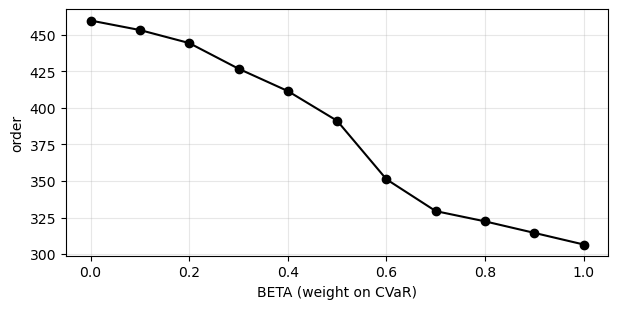

Figure: the order falls from 459.7 at BETA 0 to 306.6 at BETA 1; the drop at each step of 0.1 is [6.5, 8.9, 17.5, 15.3, 20.3, 40.0, 21.8, 7.0, 7.9, 7.9].


In [8]:
import matplotlib.pyplot as plt

DIAL = [b / 10 for b in range(11)]
dial_orders = []
for b in DIAL:
    mc.setObjective((1 - b) * profit.sum() / SCENARIOS + b * (nu - excess.sum() / TAIL), GRB.MAXIMIZE)
    mc.optimize()
    dial_orders.append(order.X)

plt.figure(figsize=(7, 3.2))
plt.plot(DIAL, dial_orders, "o-", color="black")
plt.xlabel("BETA (weight on CVaR)")
plt.ylabel("order")
plt.grid(alpha=0.3)
plt.show()
steps = [round(a - b, 1) for a, b in zip(dial_orders, dial_orders[1:])]
print(f"Figure: the order falls from {dial_orders[0]:.1f} at BETA 0 to {dial_orders[-1]:.1f} at BETA 1; "
      f"the drop at each step of 0.1 is {steps}.")

## VaR as an integer program

VaR is a threshold `worst` that profit must beat in all but 100 scenarios. Which 100 is the
model's choice, so each scenario gets a binary `excused`; an excused scenario's constraint is
switched off by a big-M term, and at most `TAIL` may be excused. That is one binary per scenario: a
MIP, where CVaR was an LP.

In [9]:
BIG_M = RETAIL * max(demand) - (RECOVER - COST) * max(demand)     # wider than any two profits apart
mv = gp.Model("VaR", env=env)
tolerance.apply(mv)
v_order = mv.addVar(name="order")
v_profit = mv.addVars(SCENARIOS, lb=-GRB.INFINITY, name="profit")
v_sales = mv.addVars(SCENARIOS, ub=demand, name="sales")
v_discount = mv.addVars(SCENARIOS, name="discount")
mv.addConstrs((v_profit[i] == RETAIL * v_sales[i] - COST * v_order + RECOVER * v_discount[i] for i in range(SCENARIOS)), name="profit")
mv.addConstrs((v_sales[i] + v_discount[i] == v_order for i in range(SCENARIOS)), name="demand")

worst = mv.addVar(lb=-GRB.INFINITY, name="worst")
excused = mv.addVars(SCENARIOS, vtype=GRB.BINARY, name="excused")
mv.addConstrs((worst - BIG_M * excused[i] <= v_profit[i] for i in range(SCENARIOS)), name="worst")
mv.addConstr(excused.sum() <= TAIL, name="budget")
mv.setObjective(worst, GRB.MAXIMIZE)
mv.update()
print(mv.NumVars, "variables,", mv.NumIntVars, "of them binary,", mv.NumConstrs, "constraints")

1602 variables, 400 of them binary, 1201 constraints


Predict before running: will the VaR order land above or below the CVaR order?

Then read the tail two ways: from the model's own `profit` variables, and by scoring the order
against every scenario, as for CVaR.

In [10]:
mv.optimize()
var_order = v_order.X
var_objective = mv.ObjVal
model_says = sorted(v_profit[i].X for i in range(SCENARIOS))
var_profits = [RETAIL * min(var_order, d) - COST * var_order + RECOVER * max(0, var_order - d) for d in demand]
scored = sorted(var_profits)
print(f"VaR order {var_order:.4f}   objective (the threshold) {var_objective:.4f}   MIP gap {mv.MIPGap:.1e}")
print(f"tail CVaR from the model's profit variables {mean(model_says[:TAIL]):10.2f}")
print(f"tail CVaR from scoring the order           {mean(scored[:TAIL]):10.2f}")

VaR order 334.6840   objective (the threshold) 4350.8916   MIP gap 0.0e+00
tail CVaR from the model's profit variables    -456.49
tail CVaR from scoring the order              3220.62


Same order, two very different tails. Which one is true, and why does the model's own number
disagree? Count the scenarios where the two profits differ, and check whether they are the ones
the model excused.

In [11]:
differ = [i for i in range(SCENARIOS) if abs(v_profit[i].X - var_profits[i]) > tolerance.FEASIBILITY_ATOL]
excused_ones = [i for i in range(SCENARIOS) if excused[i].X > 0.5]
print(f"{len(differ)} scenarios where the model's profit differs from the scored profit")
print(f"{len(excused_ones)} scenarios excused;  {len(set(differ) & set(excused_ones))} of the differing ones are excused")

75 scenarios where the model's profit differs from the scored profit
100 scenarios excused;  75 of the differing ones are excused


## Four orders, side by side

The risk-neutral order, the half-and-half mix, CVaR and VaR, each scored against the same 400
scenarios. Before running, say which order you expect to win each column.

In [12]:
compare = {"risk-neutral": neutral_order, "mix": mix_order, "CVaR": cvar_order, "VaR": var_order}
print(f"{'':13} {'order':>9} {'mean':>9} {'VaR':>9} {'CVaR':>9} {'worst':>9}")
for name, q in compare.items():
    pr = sorted(RETAIL * min(q, d) - COST * q + RECOVER * max(0, q - d) for d in demand)
    print(f"{name:13} {q:9.2f} {mean(pr):9.2f} {pr[TAIL]:9.2f} {mean(pr[:TAIL]):9.2f} {pr[0]:9.2f}")

                  order      mean       VaR      CVaR     worst
risk-neutral     459.74   4620.83   3725.62   2595.35  -1698.36
mix              391.18   4453.98   4068.41   2938.14  -1355.57
CVaR             306.61   3810.80   3985.92   3285.41   -932.72
VaR              334.68   4068.32   4350.89   3220.62  -1073.09


Does each order win the column it was built for? Which order would you give a vendor who can
survive a bad quarter but not a bad day, and which number in the table would you show them?

---

# Now the streamlined version

The same models, built in the package once: `newsvendor.solve_cvar` for the dial (any `beta`),
`newsvendor.solve_var` for the MIP, and `newsvendor.tail_stats` for the two tail numbers. Both
solvers score the order against every scenario before returning profits, for the reason found
above.

In [13]:
from orteach import newsvendor as nv
from orteach.tolerance import AGREEMENT_RTOL, rel_diff

pkg = {"risk-neutral": nv.solve_cvar(demand, COST, RETAIL, RECOVER, ALPHA, beta=0.0, env=env),
       "mix": nv.solve_cvar(demand, COST, RETAIL, RECOVER, ALPHA, beta=0.5, env=env),
       "CVaR": nv.solve_cvar(demand, COST, RETAIL, RECOVER, ALPHA, beta=1.0, env=env),
       "VaR": nv.solve_var(demand, COST, RETAIL, RECOVER, ALPHA, env=env)}
for name, r in pkg.items():
    v, c = nv.tail_stats(r.profits, ALPHA)
    print(f"{name:13} order {r.order:9.4f}   mean {r.expected_profit:9.2f}   VaR {v:9.2f}   CVaR {c:9.2f}")

risk-neutral  order  459.7374   mean   4620.83   VaR   3725.62   CVaR   2595.35
mix           order  391.1796   mean   4453.98   VaR   4068.41   CVaR   2938.14
CVaR          order  306.6096   mean   3810.80   VaR   3985.92   CVaR   3285.41
VaR           order  334.6840   mean   4068.32   VaR   4350.89   CVaR   3220.62


## The agreement assertion

Every optimal order here is unique (checked when this was written, by minimising and maximising the
order over each optimal set), so the orders are compared directly. So are the two objective values,
each against the package's honestly scored tail number, which is the claim that the model's
objective, unlike its profit variables, is true.

In [14]:
cvar_v, cvar_c = nv.tail_stats(pkg["CVaR"].profits, ALPHA)
var_v, var_c = nv.tail_stats(pkg["VaR"].profits, ALPHA)
checks = [("risk-neutral order", neutral_order, pkg["risk-neutral"].order),
          ("mix order", mix_order, pkg["mix"].order),
          ("CVaR order", cvar_order, pkg["CVaR"].order),
          ("VaR order", var_order, pkg["VaR"].order),
          ("CVaR objective = scored CVaR", cvar_objective, cvar_c),
          ("VaR objective = scored VaR", var_objective, var_v),
          ("hand-scored CVaR", mean(sorted(cvar_profits)[:TAIL]), cvar_c),
          ("hand-scored VaR", sorted(var_profits)[TAIL], var_v)]
for b, q in zip(DIAL, dial_orders):
    checks.append((f"dial {b:.1f}", q, nv.solve_cvar(demand, COST, RETAIL, RECOVER, ALPHA, beta=b, env=env).order))

worst = max(rel_diff(h, k) for _, h, k in checks)
print(f"{len(checks)} comparisons")
for name, hand, packaged in checks[:6]:
    print(f"  {name:30} hand {hand:10.4f}   package {packaged:10.4f}   rel {rel_diff(hand, packaged):.2e}")
print("  ...")
assert worst < AGREEMENT_RTOL, f"notebook and package disagree by {worst:.2e}"
print(f"\nnotebook and package agree to {worst:.1e}")

19 comparisons
  risk-neutral order             hand   459.7374   package   459.7374   rel 0.00e+00
  mix order                      hand   391.1796   package   391.1796   rel 0.00e+00
  CVaR order                     hand   306.6096   package   306.6096   rel 0.00e+00
  VaR order                      hand   334.6840   package   334.6840   rel 0.00e+00
  CVaR objective = scored CVaR   hand  3285.4101   package  3285.4101   rel 1.38e-16
  VaR objective = scored VaR     hand  4350.8916   package  4350.8916   rel 0.00e+00
  ...

notebook and package agree to 1.4e-16


---

## Where to take this next

- Set `ALPHA` to 0.95. The tail is now 20 scenarios. Predict which orders move most, then check.
- With a full licence, set `SCENARIOS` to 1000. Does the CVaR order settle, or keep moving?
- Give the VaR model's objective a tiny positive weight on average profit, so selling a copy is
  never worth nothing to it. Does the model's own tail now agree with the scored one, and does the
  VaR order change?
- Add the worst-case order from `newsvendor.ipynb` to the comparison table. Which column does it
  win, and at what cost in the others?